Sel 1: muat data

In [1]:
from pathlib import Path

from review_nlp.ingestion.transform import refilter
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from review_nlp.sentiment.labels import rating_to_label

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FILE = ROOT / "data/raw/com.whatsapp_2026-08-19_2026-11-17.parquet"
df = pd.read_parquet(FILE)
df = refilter(df)
df["reviewed_at"] = pd.to_datetime(df["reviewed_at"])
print(df.shape)
df.dtypes

(10400, 10)


external_id                  str
user_hash                    str
rating                     int64
text_raw                     str
thumbs_up                  int64
app_version                  str
reviewed_at       datetime64[us]
week_index                 int64
lang                         str
exclude_reason               str
dtype: object

Sel 2: kualitas data dan alasan eksklusi

In [2]:
status = df["exclude_reason"].fillna("dipakai")
print(status.value_counts())
print((status.value_counts(normalize=True) * 100).round(1))

used = df[df["exclude_reason"].isna()].copy()
print("\nDipakai:", len(used), "| teks duplikat:", used["text_raw"].duplicated().sum())

exclude_reason
dipakai           5846
too_short         4473
non_indonesian      80
empty                1
Name: count, dtype: int64
exclude_reason
dipakai           56.2
too_short         43.0
non_indonesian     0.8
empty              0.0
Name: proportion, dtype: float64

Dipakai: 5846 | teks duplikat: 58


Sel 3: distribusi rating dan label

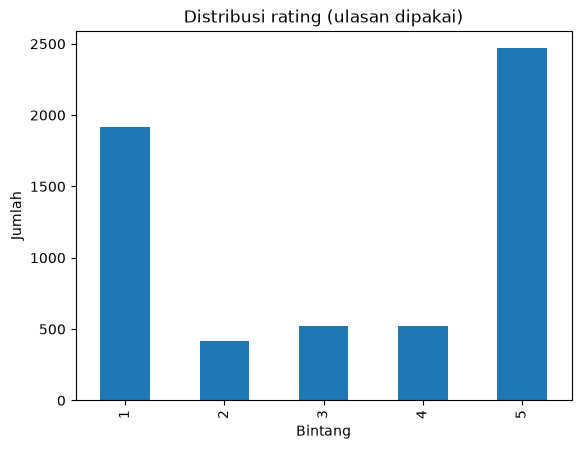

rating
1    0.328
2    0.071
3    0.089
4    0.090
5    0.422
Name: count, dtype: float64

Proporsi label:
label
positif    0.512
negatif    0.399
netral     0.089
Name: proportion, dtype: float64


In [3]:
counts = used["rating"].value_counts().sort_index()
ax = counts.plot(kind="bar", title="Distribusi rating (ulasan dipakai)")
ax.set_xlabel("Bintang")
ax.set_ylabel("Jumlah")
plt.savefig(ROOT / "docs/images/rating_dist.png", dpi=150, bbox_inches="tight")
plt.show()

print((counts / counts.sum()).round(3))
used["label"] = used["rating"].map(rating_to_label)
print("\nProporsi label:")
print(used["label"].value_counts(normalize=True).round(3))

Sel 4: ulasan pendek vs ulasan dipakai (bias seleksi)

In [4]:
short = df[df["exclude_reason"] == "too_short"]
perbandingan = pd.DataFrame(
    {
        "dipakai": used["rating"].value_counts(normalize=True).sort_index(),
        "too_short": short["rating"].value_counts(normalize=True).sort_index(),
    }
).round(3)
perbandingan

,dipakai,too_short
rating,,
1,0.328,0.053
2,0.071,0.017
3,0.089,0.029
4,0.090,0.073
5,0.422,0.828


Sel 5: tren per minggu (proporsi sentimen)

Ulasan dipakai per minggu: min 421 | maks 500
Margin kira-kira ±95% proporsi negatif (poin persen): min 4.4 | maks 4.7


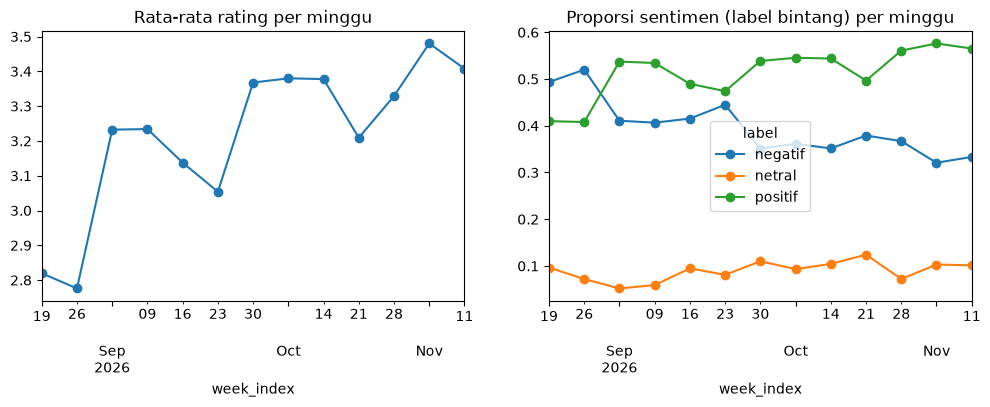

label,negatif,netral,positif
week_index,,,
2026-08-19,0.494,0.097,0.410
2026-08-26,0.520,0.072,0.408
2026-09-02,0.411,0.052,0.537
2026-09-09,0.407,0.059,0.534
2026-09-16,0.415,0.095,0.490
2026-09-23,0.445,0.081,0.474
2026-09-30,0.351,0.110,0.539
2026-10-07,0.361,0.093,0.545
2026-10-14,0.352,0.105,0.544


In [5]:
weekly = used.groupby("week_index").agg(n=("rating", "size"), rating_mean=("rating", "mean"))
share = used.groupby("week_index")["label"].value_counts(normalize=True).unstack().fillna(0)

margin = (1.96 * np.sqrt(share["negatif"] * (1 - share["negatif"]) / weekly["n"]) * 100).round(1)
print("Ulasan dipakai per minggu: min", weekly["n"].min(), "| maks", weekly["n"].max())
print("Margin kira-kira ±95% proporsi negatif (poin persen): min", margin.min(), "| maks", margin.max())

for d in (weekly, share):
    d.index = pd.Timestamp("2026-08-19") + pd.to_timedelta(d.index * 7, unit="D")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
weekly["rating_mean"].plot(ax=ax[0], marker="o", title="Rata-rata rating per minggu")
share.plot(ax=ax[1], marker="o", title="Proporsi sentimen (label bintang) per minggu")
fig.savefig(ROOT / "docs/images/weekly_trend.png", dpi=150, bbox_inches="tight")
plt.show()
share.round(3)

Sel 6: volume asli per minggu dan cakupan hari

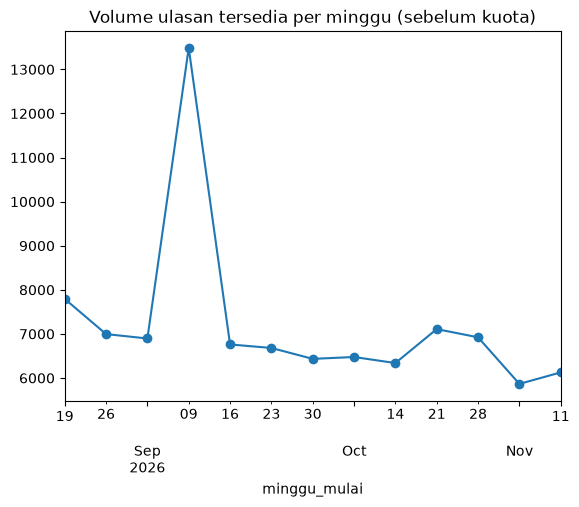

Hari terisi: 91 dari 91 | per hari: min 48 | maks 358


,week_index,ulasan_tersedia,ulasan_diambil,minggu_mulai
0,0,7794,800,2026-08-19
1,1,6996,800,2026-08-26
2,2,6896,800,2026-09-02
3,3,13487,800,2026-09-09
4,4,6761,800,2026-09-16
5,5,6681,800,2026-09-23
6,6,6434,800,2026-09-30
7,7,6476,800,2026-10-07
8,8,6339,800,2026-10-14
9,9,7109,800,2026-10-21


In [6]:
VOL = ROOT / "data/raw/com.whatsapp_2026-08-19_2026-11-17_weekly_volume.csv"
vol = pd.read_csv(VOL)
vol["minggu_mulai"] = pd.Timestamp("2026-08-19") + pd.to_timedelta(vol["week_index"] * 7, unit="D")
ax = vol.plot(
    x="minggu_mulai",
    y="ulasan_tersedia",
    marker="o",
    legend=False,
    title="Volume ulasan tersedia per minggu (sebelum kuota)",
)
plt.savefig(ROOT / "docs/images/weekly_volume.png", dpi=150, bbox_inches="tight")
plt.show()

per_day = df.groupby(df["reviewed_at"].dt.date).size()
print("Hari terisi:", len(per_day), "dari 91 | per hari: min", per_day.min(), "| maks", per_day.max())
vol

Sel 7: panjang teks

count    5846.0
mean       13.2
std        13.1
min         1.0
25%         5.0
50%         9.0
75%        16.0
max       105.0
Name: n_words, dtype: float64


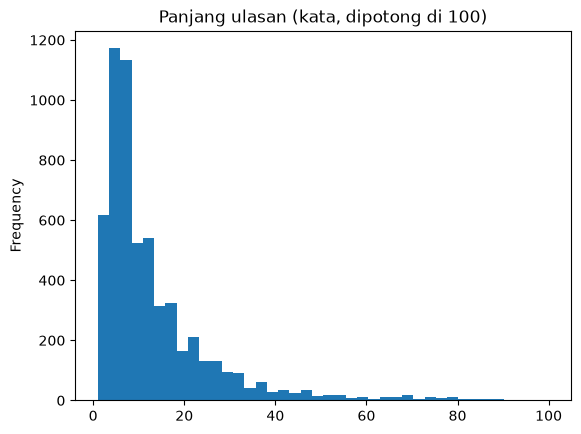

In [7]:
used["n_words"] = used["text_raw"].str.split().str.len()
print(used["n_words"].describe().round(1))
ax = used["n_words"].clip(upper=100).plot(
    kind="hist", bins=40, title="Panjang ulasan (kata, dipotong di 100)"
)
plt.show()

Sel 8: sebaran versi aplikasi

In [8]:
vc = used["app_version"].value_counts()
print("Tanpa versi:", round(used["app_version"].isna().mean(), 3))
print("Jumlah versi:", len(vc), "| versi dengan >= 200 ulasan:", int((vc >= 200).sum()))

by_version = (
    used.groupby("app_version")
    .agg(n=("rating", "size"), rating_mean=("rating", "mean"))
    .query("n >= 200")
    .sort_values("n", ascending=False)
)
by_version.round(2)

Tanpa versi: 0.222
Jumlah versi: 183 | versi dengan >= 200 ulasan: 11


,n,rating_mean
app_version,,
2.26.41.77,333,3.32
2.26.33.76,288,2.95
2.26.37.73,278,3.05
2.26.38.73,274,3.27
2.26.36.74,271,3.04
2.26.42.74,260,3.40
2.26.40.76,256,3.45
2.26.34.81,239,3.13
2.26.32.83,239,2.87


Sel 9: periksa filter bahasa (baca 50 contoh)

In [9]:
dropped = df[df["exclude_reason"] == "non_indonesian"]
print("Dibuang karena bukan bahasa Indonesia:", len(dropped))
dropped[["lang", "text_raw"]].sample(min(50, len(dropped)), random_state=42)

Dibuang karena bukan bahasa Indonesia: 80


,lang,text_raw
3619,en,Great app love it
146,en,top apps good
3243,en,"Please don't block me, I'm a WhatsApp admin, I..."
3626,en,"Hi, WhatsApp! i recommended the chat be new ag..."
2925,en,very very good makes communication easier for me
3514,en,It's really a great app. It can delivers unmat...
1588,en,Good the best
8320,en,"Please, WhatsApp team developers, add a chat b..."
679,en,"What's wrong with WhatsApp, why is it that eve..."
1932,en,Is the best


Sel 10: hari tersibuk

In [10]:
harian = (
    used.groupby([used["week_index"], used["reviewed_at"].dt.date])
    .agg(n=("rating", "size"), negatif=("label", lambda s: (s == "negatif").mean()))
    .reset_index()
)
harian["porsi_minggu"] = harian["n"] / harian.groupby("week_index")["n"].transform("sum")
harian.sort_values("n", ascending=False).head(8).round(3)

,week_index,reviewed_at,n,negatif,porsi_minggu
21,3,2026-09-09,170,0.365,0.402
15,2,2026-09-03,83,0.482,0.172
89,12,2026-11-16,83,0.313,0.187
67,9,2026-10-25,82,0.390,0.179
2,0,2026-08-21,82,0.500,0.176
40,5,2026-09-28,80,0.350,0.166
39,5,2026-09-27,80,0.488,0.166
35,5,2026-09-23,80,0.438,0.166


In [11]:
hari = harian.sort_values("n", ascending=False).iloc[0]["reviewed_at"]
sub = used[(used["reviewed_at"].dt.date == hari) & (used["label"] == "negatif")]
print("Hari tersibuk:", hari, "| ulasan negatif:", len(sub))
sub[["rating", "text_raw"]].sample(min(20, len(sub)), random_state=0)

Hari tersibuk: 2026-09-09 | ulasan negatif: 62


,rating,text_raw
2771,1,gabisa dibuat chat
2799,1,tidak support ram 2 gb
2835,1,wa kontol koyok taek
3070,1,"aku ngasih bintang satu karna,whastapp nya tid..."
3086,1,Wa g bisa di aktipkan
2868,1,"Kenapa androit 0,5 egk bisa menggunakan whatsapp"
2466,1,Tidk bisa di apdate
3057,2,Kenapa whatsap saya ga ke buka
2416,2,Perbaharui whatshapp kadaluwarsa
3006,1,aplikasi wa ini kurang memuaskan khususnya mas...


Sel 11: apakah ulasan tanpa versi bias

In [12]:
used["tanpa_versi"] = used["app_version"].isna()
print("Proporsi tanpa versi menurut bintang:")
print(used.groupby("rating")["tanpa_versi"].mean().round(3))
print("\nProporsi tanpa versi menurut minggu:")
print(used.groupby("week_index")["tanpa_versi"].mean().round(3).to_string())

Proporsi tanpa versi menurut bintang:
rating
1    0.215
2    0.202
3    0.207
4    0.204
5    0.237
Name: tanpa_versi, dtype: float64

Proporsi tanpa versi menurut minggu:
week_index
0     0.193
1     0.202
2     0.187
3     0.248
4     0.226
5     0.235
6     0.234
7     0.210
8     0.209
9     0.224
10    0.221
11    0.239
12    0.259


Sel 12: tabel 11 versi yang layak dibandingkan

In [13]:
tabel = (
    used.dropna(subset=["app_version"])
    .groupby("app_version")
    .agg(
        n=("rating", "size"),
        awal=("reviewed_at", "min"),
        median=("reviewed_at", "median"),
        akhir=("reviewed_at", "max"),
        rating_mean=("rating", "mean"),
        negatif=("label", lambda s: (s == "negatif").mean()),
    )
    .query("n >= 200")
    .sort_values("median")
)
tabel.round(3)

/tmp/ipykernel_55609/4107063378.py:15: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  tabel.round(3)


,n,awal,median,akhir,rating_mean,negatif
app_version,,,,,,
2.26.32.83,239,2026-08-20 23:11:16,2026-08-25 11:55:49.000,2026-11-11 20:45:49,2.866,0.477
2.26.33.76,288,2026-08-29 07:41:51,2026-09-02 13:27:28.000,2026-11-11 20:22:31,2.951,0.472
2.26.34.81,239,2026-09-04 05:13:37,2026-09-08 09:41:41.000,2026-11-13 22:46:41,3.134,0.423
2.26.36.74,271,2026-09-17 15:02:52,2026-09-22 10:22:02.000,2026-11-04 18:50:28,3.044,0.435
2.26.37.73,278,2026-09-22 14:53:48,2026-09-28 08:18:18.000,2026-11-15 08:57:05,3.054,0.450
2.26.38.73,274,2026-10-01 04:50:10,2026-10-06 09:48:15.000,2026-11-16 08:15:44,3.274,0.391
2.26.39.79,209,2026-10-10 05:53:49,2026-10-13 20:53:44.000,2026-11-08 06:16:54,3.268,0.373
2.26.40.76,256,2026-10-11 07:40:10,2026-10-19 23:23:03.500,2026-11-17 12:49:38,3.453,0.336
2.26.41.77,333,2026-10-19 16:18:17,2026-10-26 20:36:13.000,2026-11-17 14:40:06,3.321,0.348


In [14]:
def bandingkan(a, b):
    xa = used.loc[used["app_version"] == a, "label"] == "negatif"
    xb = used.loc[used["app_version"] == b, "label"] == "negatif"
    pa, pb, na, nb = xa.mean(), xb.mean(), len(xa), len(xb)
    se = np.sqrt(pa * (1 - pa) / na + pb * (1 - pb) / nb)
    d = pb - pa
    return {
        "versi_a": a, "versi_b": b, "n_a": na, "n_b": nb,
        "neg_a": round(pa, 3), "neg_b": round(pb, 3),
        "selisih": round(d, 3), "ci95": (round(d - 1.96 * se, 3), round(d + 1.96 * se, 3)),
    }
    

Sel 13: diagnosis 9 September

In [15]:
H = pd.Timestamp("2026-09-09").date()
hari = df[df["reviewed_at"].dt.date == H]
lain = df[(df["week_index"] == 3) & (df["reviewed_at"].dt.date != H)]
print("Ulasan di sampel: 9 Sep =", len(hari), "| sisa minggu 3 =", len(lain))
print(
    pd.DataFrame(
        {
            "9_sep": hari["rating"].value_counts(normalize=True).sort_index(),
            "sisa_minggu_3": lain["rating"].value_counts(normalize=True).sort_index(),
        }
    ).round(3)
)
print("too_short:", round((hari["exclude_reason"] == "too_short").mean(), 3),
      "vs", round((lain["exclude_reason"] == "too_short").mean(), 3))
print("Teks duplikat pada 9 Sep:", int(hari["text_raw"].duplicated().sum()))
print(hari["app_version"].value_counts(dropna=False).head(5))
hari[["rating", "text_raw"]].sample(20, random_state=0)

Ulasan di sampel: 9 Sep = 358 | sisa minggu 3 = 442
        9_sep  sisa_minggu_3
rating                      
1       0.179          0.265
2       0.039          0.038
3       0.047          0.059
4       0.067          0.072
5       0.668          0.566


too_short: 0.525 vs 0.414
Teks duplikat pada 9 Sep: 87
app_version
2.26.27.85    137
NaN            98
2.26.34.81     50
2.26.25.80      5
2.26.26.73      4
Name: count, dtype: int64


,rating,text_raw
2409,5,Aplikasi android yg perfect dan sangat mudah d...
2982,5,baguss
2647,5,Ko gk bisa kebuka wa nya
2889,5,bagus layananya
2618,5,Puas
2669,1,bad
2928,5,bagus
2521,5,tolong dipermudah aplikasi whatssap nya
2462,5,gimana supaya aktif lagi wa saya
2677,4,lumayan bagus


Sel 14: proporsi berbobot volume

In [16]:
vol = pd.read_csv(VOL)
bobot = vol.set_index("week_index")["ulasan_tersedia"] / vol.set_index("week_index")["ulasan_diambil"]
used["bobot"] = used["week_index"].map(bobot)
berbobot = used.groupby("label")["bobot"].sum() / used["bobot"].sum()
pd.DataFrame(
    {"tanpa_bobot": used["label"].value_counts(normalize=True), "berbobot_volume": berbobot}
).round(3)

,tanpa_bobot,berbobot_volume
label,,
negatif,0.399,0.402
netral,0.089,0.087
positif,0.512,0.511


Sel 15: negatif per versi, dengan kontrol waktu

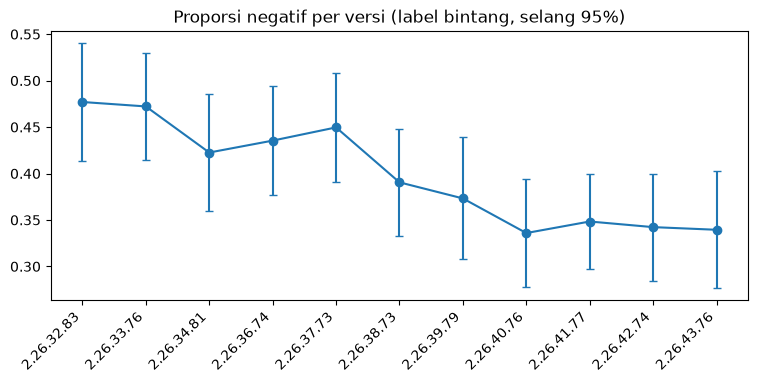

            n    neg
kelompok            
baru      642  0.332
lama       21  0.429


In [17]:
v = used[used["app_version"].isin(tabel.index)]
per_versi = (
    v.groupby("app_version")["label"]
    .agg(n="size", neg=lambda s: (s == "negatif").mean())
    .reindex(tabel.index)
)
per_versi["moe"] = 1.96 * np.sqrt(per_versi["neg"] * (1 - per_versi["neg"]) / per_versi["n"])

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.errorbar(range(len(per_versi)), per_versi["neg"], yerr=per_versi["moe"], fmt="o-", capsize=3)
ax.set_xticks(range(len(per_versi)))
ax.set_xticklabels(per_versi.index, rotation=45, ha="right")
ax.set_title("Proporsi negatif per versi (label bintang, selang 95%)")
fig.savefig(ROOT / "docs/images/negatif_per_versi.png", dpi=150, bbox_inches="tight")
plt.show()

# kontrol waktu: hanya ulasan 3 minggu terakhir, versi lama vs baru
akhir = used[(used["week_index"] >= 10) & used["app_version"].isin(tabel.index)].copy()
akhir["kelompok"] = np.where(akhir["app_version"].isin(tabel.index[:5]), "lama", "baru")
print(akhir.groupby("kelompok")["label"].agg(n="size", neg=lambda s: (s == "negatif").mean()).round(3))

Sel 16: karakterisasi lonjakan 9 September (akhir notebook 01)

In [18]:
V = "2.26.27.85"
sv = df[df["app_version"] == V]
print("Ulasan versi", V, "di sampel:", len(sv), "| pada 9 Sep:", int((sv["reviewed_at"].dt.date == H).sum()))
print(sv.groupby(sv["reviewed_at"].dt.date).size().sort_values(ascending=False).head(5))

burst = sv[sv["reviewed_at"].dt.date == H]
print("\nSebaran jam (9 Sep):")
print(burst.groupby(burst["reviewed_at"].dt.hour).size().to_string())
print("\nNama pengguna unik:", burst["user_hash"].nunique(), "dari", len(burst))
print("Teks unik:", burst["text_raw"].nunique(), "dari", len(burst))
print("Bintang:", burst["rating"].value_counts(normalize=True).sort_index().round(3).to_dict())
print(burst["text_raw"].value_counts().head(8))

per_hari = df.groupby(df["reviewed_at"].dt.date)["text_raw"].apply(lambda s: s.duplicated().mean())
print("\nRasio teks duplikat per hari:")
print(per_hari.describe().round(3))
print("9 Sep:", round(per_hari[H], 3))

Ulasan versi 2.26.27.85 di sampel: 307 | pada 9 Sep: 137
reviewed_at
2026-09-09    137
2026-09-10     18
2026-10-06      7
2026-08-31      6
2026-08-24      5
dtype: int64

Sebaran jam (9 Sep):
reviewed_at
4      2
5      5
6     10
7     11
8      9
9      3
10    13
11     9
12    16
13     8
14     3
15     3
16    13
17     7
18     5
19     6
20     5
21     3
22     5
23     1

Nama pengguna unik: 137 dari 137
Teks unik: 107 dari 137
Bintang: {1: 0.146, 2: 0.029, 3: 0.036, 4: 0.044, 5: 0.745}
text_raw
Ok              9
Bagus           7
Mantap          4
sangat bagus    4
baik            4
Baik            3
oke             2
bagus           2
Name: count, dtype: int64

Rasio teks duplikat per hari:
count    91.000
mean      0.125
std       0.039
min       0.015
25%       0.099
50%       0.127
75%       0.148
max       0.243
Name: text_raw, dtype: float64
9 Sep: 0.243


### Pembaruan: filter bahasa dan 9 September
- Setelah perbaikan (deteksi huruf kecil + kata penanda Indonesia), ulasan non_indonesian turun dari
  158 menjadi 80. Dari 50 contoh baru, 5 (10%) sebenarnya Indonesia/campuran; dampak ke data < 0,2%.
- 9 Sep: 137 dari 358 ulasan berasal dari versi 2.26.27.85 (307 ulasan total versi itu), tersebar
  sepanjang hari (maks 16 per jam). Rasio teks duplikat tertinggi dari semua hari (0,243 vs kuartil
  ketiga 0,148). Penyebab tidak dapat dipastikan. Menghapus hari itu dari data latih tidak
  mengubah macro-F1 (selisih 0,005).
- Proporsi negatif turun dari ~0,50 (minggu 0-1) ke ~0,33 (minggu 11-12). Efek versi tidak dapat
  dipisahkan dari efek waktu (versi lama hanya 21 ulasan di 3 minggu terakhir).